# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
System  : Windows 11


In [3]:
%pip --version

pip 25.3 from C:\Users\Imane SAMIR\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pip (python 3.14)

Note: you may need to restart the kernel to use updated packages.


### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [8]:
!ollama --version

ollama version is 0.40.6


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [9]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [10]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5"   # Model 1
MODEL2 = "gemma3"    # Model 2 (used in the comparison parts)

In [13]:
!ollama pull {MODEL}

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [14]:
!ollama list

NAME              ID              SIZE      MODIFIED      
qwen3.5:latest    56671c2ab938    6.6 GB    4 seconds ago    
llama3.1:8b       46e0c10c039e    4.9 GB    4 weeks ago      


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [17]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [20]:
print(ask("Say hello in one sentence.", think=False))
!ollama ps

[3.4s]
Hello! How can I assist you today?
NAME              ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:latest    56671c2ab938    5.6 GB    100% GPU     4096       llamacpp    4 minutes from now    


In [21]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[27.8s]
Artificial intelligence refers to the simulation of human intelligence processes by computer systems. These advanced machines can perform tasks that typically require human cognition, such as learning, reasoning, and problem-solving. By analyzing vast amounts of data, AI algorithms enable automation in fields ranging from healthcare to transportation. While some forms follow strict rules, modern systems often use machine learning to adapt and improve over time. Ultimately, the goal is to create tools that assist humans in achieving complex objectives more efficiently than traditional methods.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[62.1s]
Imagine your computer is like a really fast calculator that follows strict rules: *If you press this button, it does that thing.* That's what old computers do.

**Artificial Intelligence (AI)** is a special kind of computer that acts more like a hum

In [22]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[352.7s]
Artificial intelligence is a branch of computer science focused on creating systems that can perform tasks requiring human intelligence. These technologies process vast amounts of data to identify patterns, make decisions, and solve problems without direct human intervention. Machine learning and deep learning are key components that allow AI models to evolve and improve through experience over time. You can see this technology in action through virtual assistants like Siri, recommendation algorithms on streaming services, and self-driving cars. Ultimately, the field aims to develop increasingly sophisticated tools that augment human capabilities across various industries.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[405.5s]
Imagine you have a very smart robot friend named "AI."

That's what Artificial Intelligence is! The word sounds complicated, but it just means **"thinking computers.

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**
1. Yes, for two reasons: First the prompt sets the audience so the depth and structure change, starting with plain language then using analogies and finally introducing technical terms. Second the model samples its output so running the prompt again can produce different text. I saw this happen directly when I ran the cell two times.
2. No, Python talk to localhost:11434, the Ollama server on my own machine.
3. Locally on my NVIDIA RTX 5080 GPU (ollama ps showed 100% GPU).
4. It still worked, because the model stored on my computer and the server is local. Only the ollama pull command needs internet.

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [24]:
!ollama ps
!nvidia-smi --query-gpu=name,power.draw,clocks.sm,clocks.max.sm,memory.used,utilization.gpu --format=csv

NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 
name, power.draw [W], clocks.current.sm [MHz], clocks.max.sm [MHz], memory.used [MiB], utilization.gpu [%]
NVIDIA GeForce RTX 5080 Laptop GPU, 16.95 W, 180 MHz, 3090 MHz, 5606 MiB, 0 %


In [26]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[36.0s]
Good morning, everyone. Please take your seats. Today we are going to explore a fundamental structure in graph theory and computer science: the **Directed Acyclic Graph**, commonly abbreviated as a **DAG**.

Please follow along as I break down this concept into five key components for today’s lecture notes.

### 1. Definition
A Directed Acyclic Graph (DAG) is a specific type of graph data structure that combines two distinct properties:
*   **Directed:** Every edge in the graph has a direction. If we have vertices $u$ and $v$, an edge $u \to v$ implies a relationship from $u$ to $v$, but not necessarily vice versa.
*   **Acyclic:** The graph contains no cycles. This means there is no path that starts and ends at the same vertex (e.g., you cannot start at A, travel through some nodes, and return to A).

Together, these properties ensure that information or dependencies flow strictly in one direction without loops. In mathematical terms, a DAG is equivalent to having a **topologi

In [27]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[29.9s]
Hello! Come on in and have a seat. Don't worry if this looks complicated right now; graph theory can feel abstract until we ground it in something concrete. Today, we are going to talk about **DAGs**.

Break down the word first: **Directed Acyclic Graph**. That sounds like three scary words, but let’s unpack them one by one, and then I’ll show you how they fit together using a recipe for a cake.

### 1. The Three Parts

Imagine you are mapping out a process.

*   **Graph:** Think of this as a map made of dots and lines.
    *   The **dots** are called "nodes." They represent objects or actions (like steps in a process).
    *   The **lines** are called "edges" or "arrows." They show how the nodes connect to one another.
*   **Directed:** The lines have arrows on them. This means flow only goes one way. If an arrow points from Dot A to Dot B, you move from A to B. You cannot go backward.
*   **Acyclic:** "Cyclic" means a cycle—a loop where you start somewhere and eventually end 

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

> The two prompts have the **role** which is the one that will said the speech: a university professor so in both cases the model talked like a teacher but the role by itself did not decide what it said The **context** who will recieve this informations (the audience) is made the biggest difference in prompt_a there was no audience so the model assumed experts and used formal definitions an adjacency matrix and code in prompt_b the audience was a first-year student so it used a friendly tone and an everyday analogy (baking a cake). The **constraints** simple language one concrete example limited the amount of content in prompt_b has one example and no matrix or code and it ran faster 29.9 s agains 36.0 s in the first one. The **output format** was only specified in prompt_a which listed five required sections and got exactly those five. while prompt_b gave no format so the model chose its own headings. **Specificity** is what ties these together the more precisely a prompt states what to include for whom and in what shape the more predictable the answer The vaguer the prompt the more the model fills the gaps with its own defaults data.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [28]:
!ollama list

NAME              ID              SIZE      MODIFIED     
qwen3.5:latest    56671c2ab938    6.6 GB    44 hours ago    
llama3.1:8b       46e0c10c039e    4.9 GB    5 weeks ago     


In [29]:
!ollama show {MODEL}

  Model
    architecture        qwen35    
    parameters          9.0B      
    context length      262144    
    embedding length    4096      
    quantization        Q4_K_M    
    requires            0.30.0    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [30]:
!ollama ps

NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [31]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,llama3.1:8b,4.92,llama,8.0B,Q4_K_M


Currently loaded in memory:


""


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

> The ollama list command gives me the list of the models which are already downloaded on my computer including the name and tag, the ID, disk size, and the modification date. As far as my case is concerned, it included qwen3.5:latest (6.6 GB) and llama3.1:8b (4.9 GB). The ollama ps command tells me only about those models which are present in memory right now including the ID, the memory size, whether the process runs on the CPU or GPU, the context size, the runner, and the time to unload. For instance, after prompting, I got qwen3.5:latest with 5.6 GB, 100% GPU, context size 4096.

> A downloaded model refers to a collection of files that exist in the disk. It occupies disk space but does not consume any amount of RAM or VRAM and is not able to process any request. On the other hand, a loaded model refers to a model that has been loaded from disk into memory (VRAM in my case, because the process was done entirely using the GPU). The loading process takes a few seconds whenever a model is used for the first time. After that, Ollama maintains the model in memory for a few minutes.


## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [32]:
!ollama pull {MODEL2}
!ollama list

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 325 KB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 1.1 MB/2.5 GB                  pulling manifest 
pul

NAME              ID              SIZE      MODIFIED               
gemma3:latest     68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:latest    56671c2ab938    6.6 GB    44 hours ago              
llama3.1:8b       46e0c10c039e    4.9 GB    5 weeks ago               


### Exercise 7 — Same prompt, different models

In [33]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5

Here's a Python function that determines whether a number is prime, complete with type hints, documentation, algorithm explanation, and time complexity analysis.

```python
import math
from typing import Union

def is_prime(n: int) -> bool:
    """
    Determine whether an integer n is a prime number.

    A prime number is a natural number greater than 1 that has no positive divisors 
    other than 1 and itself.

    Args:
        n (int): The integer to check for primality.

    Returns:
        bool: True if n is prime, False otherwise.

    Raises:
        TypeError: If input is not an integer.
        ValueError: If input is less than 2.

    Examples:
        >>> is_prime(7)
        True
        >>> is_prime(10)
        False
        >>> is_prime(2)
        True
        >>> is_prime(1)
        False
    """
    if not isinstance(n, int):
        raise TypeError("Input must be an integer.")
    if n < 2:
        return False

    # 2 and 3 are primes
    if n in (

Now fill in your evaluation (scores out of 5) and see the table:

In [34]:
scores = {
    MODEL:  {"Response quality /5": None, "Code correctness /5": None},
    MODEL2: {"Response quality /5": None, "Code correctness /5": None},
}  # <- replace None with your scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5,16.3,None,None
1,gemma3,20.2,None,None


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [36]:
import math
from typing import Union

def is_prime(n: int) -> bool:
    """
    Determine whether an integer n is a prime number.

    A prime number is a natural number greater than 1 that has no positive divisors 
    other than 1 and itself.

    Args:
        n (int): The integer to check for primality.

    Returns:
        bool: True if n is prime, False otherwise.

    Raises:
        TypeError: If input is not an integer.
        ValueError: If input is less than 2.

    Examples:
        >>> is_prime(7)
        True
        >>> is_prime(10)
        False
        >>> is_prime(2)
        True
        >>> is_prime(1)
        False
    """
    if not isinstance(n, int):
        raise TypeError("Input must be an integer.")
    if n < 2:
        return False

    # 2 and 3 are primes
    if n in (2, 3):
        return True
    # Eliminate even numbers and multiples of 3
    if n % 2 == 0 or n % 3 == 0:
        return False

    # Check for factors of the form 6k ± 1 up to sqrt(n)
    limit = int(math.isqrt(n)) + 1
    for i in range(5, limit, 6):
        if n % i == 0 or n % (i + 2) == 0:
            return False

    return True

In [37]:
def is_prime2(number: int) -> bool:
  """Determines whether a given number is prime.

  Algorithm:
  The function employs a simple trial division algorithm to determine primality.
  It iterates from 2 up to the square root of the input number. In each iteration,
  it checks if the number is divisible by the current iterator. If it is, the number
  is not prime, and the function immediately returns False. If the loop completes
  without finding any divisors, the number is prime, and the function returns True.

  The optimization of iterating only up to the square root is based on the
  mathematical principle that if a number 'n' has a divisor greater than its
  square root, it must also have a divisor smaller than its square root.  Therefore,
  checking divisors up to the square root is sufficient.

  Args:
    number: The integer to check for primality.

  Returns:
    True if the number is prime, False otherwise.
  
  Raises:
    TypeError: If the input is not an integer.
    ValueError: If the input is less than or equal to 1.
  """
  if not isinstance(number, int):
    raise TypeError("Input must be an integer.")
  if number <= 1:
    raise ValueError("Input must be greater than 1.")

  # Iterate from 2 up to the square root of the number
  for i in range(2, int(number**0.5) + 1):
    if number % i == 0:
      return False

  return True

In [39]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

#comparing:
def test(candidate, name):
    wrong, errors = [], []
    for n in range(-5, 2000):
        try:
            if candidate(n) != is_prime_reference(n):
                wrong.append(n)
        except Exception as e:
            errors.append(n)
    print(f"{name}:")
    print("  wrong answers :", wrong[:10] if wrong else "none")
    print("  exceptions    :", f"{len(errors)} (n = {errors[0]} to {errors[-1]})" if errors else "none")

    # fair check on valid inputs only (n >= 2)
    ok = all(candidate(n) == is_prime_reference(n) for n in range(2, 2000))
    print("  matches reference for n >= 2:", "✅ yes" if ok else "❌ no")

test(is_prime,  "qwen3.5 (is_prime)")
test(is_prime2, "gemma3 (is_prime2)")
assert all(is_prime(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
print("✅ qwen3.5 matches the reference on -5..2000")

qwen3.5 (is_prime):
  wrong answers : none
  exceptions    : none
  matches reference for n >= 2: ✅ yes
gemma3 (is_prime2):
  wrong answers : none
  exceptions    : 7 (n = -5 to 1)
  matches reference for n >= 2: ✅ yes
✅ qwen3.5 matches the reference on -5..2000


In [40]:
for m in (MODEL, MODEL2):
    generate("Say hi.", model=m, options={"num_predict": 20})
display(loaded_models())

,name,size_GB,in_VRAM_GB,expires_at
0,gemma3:latest,2.88,2.88,2026-10-22T15:22:26.5643332Z
1,qwen3.5:latest,5.61,5.61,2026-10-22T15:22:18.5564577Z


In [41]:
for m in (MODEL, MODEL2):
    r = results[m]
    print(f"{m}: {r['wall_s']:.1f}s | {r['eval_count']} tokens | {r['eval_count']/(r['eval_duration']/1e9):.1f} tok/s")

qwen3.5: 16.3s | 703 tokens | 85.1 tok/s
gemma3: 20.2s | 904 tokens | 147.0 tok/s


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

>gemma3 is faster in generating the output: 147.0 tokens/second compared to 85.1 tokens/second in qwen3.5, almost two times faster. However, in terms of total response time, qwen3.5 was faster (16.3 s compared to 20.2 seconds). This is due to the fact that qwen3.5 gave a shorter reply (703 tokens compared to 904 tokens in gemma3).

>Both functions were correct for each input, with the second function matching my implementation on all n ≥ 2, and qwen3.5 matching my reference implementation on all inputs from -5 to 1999 without exception. qwen3.5 used a more efficient 6k ± 1 trial division approach, and had example doctests, but the docstring incorrectly stated that ValueError would be raised if n < 2, when the function just returned False instead. gemma3 used trial division and a ValueError for n ≤ 1, but this was an alternative approach, not an incorrect one. gemma3’s documentation regarding the algorithm and complexity was also more comprehensive.

>qwen3.5 uses more: 5.61 GB of VRAM against 2.88 GB for gemma3, almost twice as much, which fits their sizes on disk (6.6 GB vs 3.4 GB). Both are loaded entirely in GPU memory.

>qwen3.5 will be a great choice to aid me in programming, since its code is correct for all inputs, and it has a better algorithm. The 16 GB of VRAM available in my RTX 5080 can easily accommodate this program. However, in case the memory was not sufficient, or I needed quick results, then gemma3 would have been a perfect choice for me.

>No. While qwen3.5 (9.0B) did slightly better in terms of correctness in this test, gemma3 was not far behind and had only half the memory and faster generation. Larger models consume more memory and are generally capable too, but the outcome ultimately depends on the task (which is very simple in this case), training and tuning. A smaller model might sometimes be the way to go if speed, memory usage or cost outweigh the difference in quality.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [44]:
!pip install -q requests

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [45]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [46]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Writing local_ai_lab/app.py


In [47]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [48]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [51]:
!py -X utf8 local_ai_lab/app.py

**Recursion** is a powerful programming technique where a function calls itself in order to solve a problem.

In Python, recursion allows you to break a complex problem down into smaller, similar sub-problems until they reach a simple case that can be solved directly.

---

### 1. The Two Essential Rules
Every recursive function must have two parts to work correctly:

1.  **The Base Case:** The condition that stops the recursion. If this isn't met, the function will call itself forever (causing an error).
2.  **The Recursive Step:** The part where the function calls itself with modified arguments that move it closer to the base case.

### 2. Classic Example: Factorial

Let's calculate the factorial of a number $n$ ($n! = n \times (n-1) \times ... \times 1$).
Mathematically, $0! = 1$.

```python
def factorial(n):
    # 1. Base Case: Stop when n is 0 or 1
    if n <= 1:
        return 1
    
    # 2. Recursive Step: Call the function with a smaller number
    return n * factorial(n - 1)


**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [52]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

## What is Recursion?

In Python, **recursion** occurs when a function calls itself to solve a problem. Instead of using a `for` or `while` loop, recursion breaks a complex problem into smaller versions of the same problem until it reaches a simple base case that can be solved directly.

Think of it like a Russian nesting doll: each function call opens up another layer of "function" until you reach the center (the base case).

---

## The Two Key Rules of Recursion

For recursion to work correctly and stop, every recursive function must have two parts:

1.  **Base Case:** A condition where the ...

{'model': 'qwen3.5', 'created_at': '2026-10-22T15:56:11.7909515Z', 'done': True, 'done_reason': 'stop', 'total_duration': 30726360700, 'load_duration': 5879272700, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 0, 'prompt_eval_duration': 101762000, 'eval_count': 2095, 'eval_duration': 24741845000, 'wall_s': 32.78192900004797}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [57]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

#chat_loop_stateless()   # <- uncomment to run

Local AI Assistant
Type 'exit' to stop.



You:  What is machine learning?



AI: **Machine learning (ML)** is a branch of artificial intelligence (AI) that enables computers and systems to learn from data, identify patterns, and make decisions with minimal human intervention.

Instead of being explicitly programmed with specific rules to perform a task (like `if user clicks here, then show ad`), machine learning algorithms analyze large amounts of historical data to find hidden structures and improve their own performance over time.

### Key Concepts

1.  **Data:** Machine learning models are only as good as the data they are trained on. They need massive datasets to learn patterns.
2.  **Algorithms:** These are the mathematical formulas that analyze the data and build a model (a predictive tool).
3.  **Training:** The process where the algorithm adjusts its internal parameters to minimize errors based on the data.
4.  **Prediction/Inference:** Once trained, the model can use what it learned to predict outcomes or make decisions on new, unseen data.

### Main 


You:  exit


In [54]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: **机器学习（Machine Learning）** 是人工智能的一个分支，它使计算机能够通过数据“学习”，并在没有明确编程的情况下完成任务。

### 1. 基本定义
传统软件依赖程序员编写规则来解决问题；而机器学习系统则从数据中学习模式，并基于这些模式做出预测或决策。换句话说，机器学习让计算机系统“自己进化”出解决问题的能力。

### 2. 核心原理
- **训练**：使用大量带有标签的数据（训练集）对模型进行训练。
- **预测/判断**：经过训练的模型可以将学到的规律应用到新数据上。
- **优化**：系统会根据新的输入不断调整自身参数，从而提升表现。

### 3. 主要类型
| 类型 | 说明 | 应用示例 |
|------|------|----------|
| **监督学习** | 使用标注数据进行训练（有正确答案） | 垃圾邮件过滤、房价预测、图像识别 |
| **无监督学习** | 未标注数据，模型自行发现结构或模式 | 客户分群、异常检测、推荐系统 |
| **强化学习** | 通过与环境交互试错来优化行为策略 | 游戏AI、机器人控制、自动驾驶 |

## ...

You: Explain reinforcement learning.
AI: Reinforcement Learning (RL) is a type of machine learning where an agent learns to make decisions by interacting with an environment to achieve a specific goal.

Unlike **supervised learning** (where you teach a computer using labeled input/output data, like a photo of a cat and the text "cat") or **unsupervised learning** (where you let a computer find patterns in raw data), Reinforcement Learning is about **learn

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [60]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

#chat_loop_memory()   # <- uncomment for interactive use


You:  hi I'm learning agentic AI



AI: Hi there! Welcome to the world of **agentic AI**! 🎯 It's an exciting field where systems can act autonomously, make decisions, and interact with environments (or humans) in meaningful ways. Here are a few starting points to kick things off:

### 🔍 Key Concepts to Explore:
1. **Agent Architectures** – How agents perceive, reason, and act (e.g., goal-driven vs. reinforcement learning).
2. **Autonomy Levels** – From simple scripted actions to full self-improvement loops.
3. **Tools & APIs** – Integrating LLMs, sensors, or other tools for real-world tasks.
4. **Frameworks** – Check out LangChain, AutoGen, or Microsoft's Semantic Kernel for building agents.

### 🛠️ Practical First Steps:
- Try a simple agent task (e.g., a chatbot that researches answers using APIs).
- Read about multi-agent systems (collaborating vs. competing agents).
- Experiment with no-code tools like **LangSmith** or **Hugging Face Spaces**.

### 🧠 Questions to Ask Yourself:
- Do you want to build *autonomous* age


You:  what subject i'm learning at the moment?



AI: Based on our conversation so far, you are currently learning **Agentic AI** (or Agentic Artificial Intelligence)! 🤖

To clarify a bit: this goes beyond standard chatbots. In **Agentic AI**, systems act autonomously—they have goals, plan steps to reach them, interact with tools/APIs, and can work in multi-agent teams to solve complex problems. It often involves frameworks like LangChain or AutoGen, as we discussed earlier!

If you'd like, I can help you dive deeper into specific areas of Agentic AI right now. For example:
- How agents make decisions (planning/reasoning).
- Memory systems for long-term tasks.
- Multi-agent collaboration patterns.

Let me know if you have a specific direction in mind! 🚀



You:  exit


In [61]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Nice to meet you, Ahmed! How can I help you today? 

You: What is my name?
AI : Your name is Ahmed! 



In [62]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Nice to meet you, Ahmed! How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

>The model only remembers the name due to the fact that we passes the name again. LLMs themselves store nothing in-between calls, and all requests to Ollama are independent, so after the answer generation, the model loses the trace of conversation.
One can see it from the printed prompt. based on source code maintains the history list, and for each new question, it sends the whole conversation as one string: User: My name is Ahmed.  Assistant: Nice to meet you, Ahmed!...  User: What is my name? Assistant:. As one can see, the name is inside the input of the second call, and the model just extracts it there and replies “Your name is Ahmed!”. In the stateless chatbot (Part 8), such a question will not work because of the first message absence.
Thus, the memory is maintained by the application, not by the model. The problem with such a way is that the prompt increases with every turn, making every request slower and sooner or later exceeding the size of the context window. 

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [63]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [64]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[38.0s]
### Code Review: `Calculator.java`

#### 1. Potential Problems
*   **Division by Zero:** The code does not validate if `b` is zero. In Java, dividing an integer by zero results in a runtime exception rather than returning infinity or NaN (which happens with floating-point types).
*   **Lack of Documentation:** There are no Javadoc comments describing the contract (throws clauses, parameters, return value), making maintenance difficult.
*   **Return Type Limitations:** Using `int` means the result cannot represent fractions. If `a = 7` and `b = 2`, the method returns `3` without indication of loss.
*   **Overflow Risk:** While less common in a simple divide operation (since smaller numbers divided by larger usually reduce magnitude), if inputs are near `Integer.MAX_VALUE`, logic assumptions might break depending on downstream usage.

#### 2. Runtime Errors
*   **`java.lang.ArithmeticException: / by zero`**: If the caller invokes `divide(a, 0)`, this class will immediately throw 

In [65]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[319.3s]
In the provided `Student` class, there are several issues—most critical ones relate to how the `age` field is handled:

### 🔴 Critical Bugs

1. **Setter Method Does Not Assign the Field**  
   ```java
   public void setAge(int age) {
       age = age;  // This only sets the local parameter, not the instance field!
   }
   ```
   The method does nothing useful. To fix it:
   ```java
   public void setAge(int age) {
       this.age = age;
   }
   ```

2. **`age` Field Is Never Initialized**  
   The constructor assigns `name`, but never sets `age`. This leaves the field at its default value of `0`, which may be misleading or inconsistent with expectations. To ensure valid initialization:
   ```java
   public Student(String name, int age) {
       this.name = name;
       this.age = age;  // Add validation here too (see below)
   }
   ```

3. **No Input Validation**  
   There's no validation on the `age` value. It should be constrained to valid ranges:
   ```java
   private stat

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [66]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[30.7s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue current academic engagement; student is performing exceptionally well with minimal attendance issues."
}


In [67]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'low', 'recommendation': 'Continue current academic engagement; student is performing exceptionally well with minimal attendance issues.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [68]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue monitoring academic progress; minimal absences suggest strong attendance and engagement."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

>Structured output is needed since the software application requires the data in a certain format in order to process it correctly. While I am only requesting "ONLY JSON" from the LLM, it might work fine in many cases, but the model will possibly add additional information or format the output incorrectly, which can lead to json.loads errors. While my extract_json function will be able to resolve some of the issues, it still cannot guarantee that the output is correctly formatted. Using Ollama structured outputs, I will be able to use the JSON Schema in format parameter in order to define the expected structure and data types. In this case, the output will have all the five necessary fields, age will be an integer, grade will be a float, and risk will only be low, medium or high. Thus, it will be easier to use the output further, for example, to insert it into a database or use in an API request.

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [69]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [70]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [71]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[17.8s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[4.0s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

>In the case of the question posed in the document, the model generated the response using the language from the document "learning by interaction with an environment with rewards and penalties" instead of providing a generic definition. However, in the case of the question not posed in the document "Quantum Computing", it responded exactly with "Information not available.", thus following the instructions and not using any of its own knowledge. This proves that the model is grounded on the document: the response is taken from the document and not from what it has learned during training.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [72]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['ai.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt']

In [73]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [74]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (18.3s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: Based on the provided CONTEXT, training deep networks (neural networks with many layers) usually requires **GPUs**.
  (9.3s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (5.0s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (4.0s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [79]:
EMBED_MODEL = "nomic-embed-text"
!ollama pull {EMBED_MODEL}      

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest 
pulling 970aa74c0a90: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 274 MB                         
pulling c71d239df917: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  11 KB                         
pulling ce4a164fc046: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   17 B                         
pulling 31df23ea7daa: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  420 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


[('deep_learning.txt', np.float64(0.6379864724165026)), ('course.txt', np.float64(0.5337386809270472))]


## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [82]:
VISION_MODEL = MODEL2   # change to a vision-capable model you have installed
IMAGE_PATH = "images.jpeg"  # put an image next to the notebook

Okay, here’s an analysis of the image:

**1. Main Objects:**

*   **Two Kittens:** The primary focus is on two adorable, fluffy kittens. One is a pale orange tabby with white markings and a pink nose, and the other is a gray tabby kitten with darker gray markings and a slightly darker nose.
*   **Circular Basket:** The kittens are sitting in a gray, circular wicker-style basket.

**2. Environment:**

*   **Indoor Setting:** The image is clearly taken indoors.
*   **Modern Furniture:** The background suggests a modern living room with a gray sofa and a gray cushion.
*   **Dark Background:** The background is intentionally dark, which helps to emphasize the kittens and the basket.

**3. Text Visible in the Image:**

*   There is no visible text within the image.

**4. Possible Interpretation:**

*   **Cuteness and Playfulness:** The image evokes feelings of cuteness, playfulness, and warmth. The kittens' inquisitive expressions (looking upwards) suggest they are curious about something, 

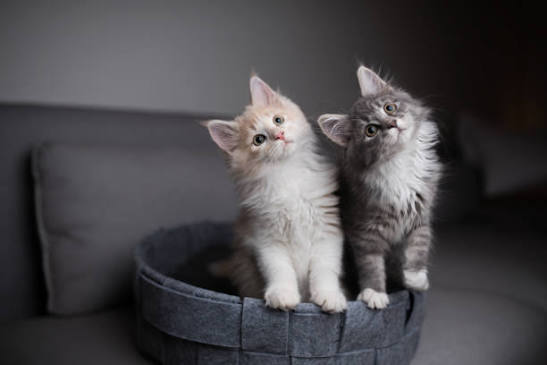

In [83]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

1. A classic large language model LLM only works with text, it takes text as input and Gives text as output. A multimodal model is different. It can take various type as input such as images. Then it connects the images to the text prompt. To do this it has a part called a vision encoder. This encoder turns the image into a set of numbers or embeddings. These embeddings can then be used by the language model. The language model combines these embeddings with the words, from the prompt. This way the model understands both the text and the image together.
2.  It is fed with the image itself and additionaly the text prompt. It has the benefit of being provided with visual data that a text-based model would not have access to like objects, colors, positions, expressions, the environment and text within the image itself. In my case, it recognized two kittens, a basket, an indoor scene and no text.
3.  Document analysis and OCR for reading scanned forms, industrial inspection to detect defects on a production line, education for explaining diagrams, preprocessing of images and surveillance analysis are all tasks that can benefit from a local vision AI. Local model may matters for images because nothing leaves the machine. Since my thesis focuses on image classification a natural use is to check images locally before they enter a classification pipeline. However a local model should not replace a trained model. The general vision model gives a description that is not always exact.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [84]:
%pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Imane SAMIR\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [86]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False, "think": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Overwriting local-ai-web/app.py


In [87]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [88]:
%pip install -q psutil

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Imane SAMIR\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [89]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [90]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5,6.55,5.61,5.61,3.32,13.13,665,87.30,49.7,None
1,gemma3,3.35,2.88,2.88,3.69,11.29,826,152.16,52.8,None


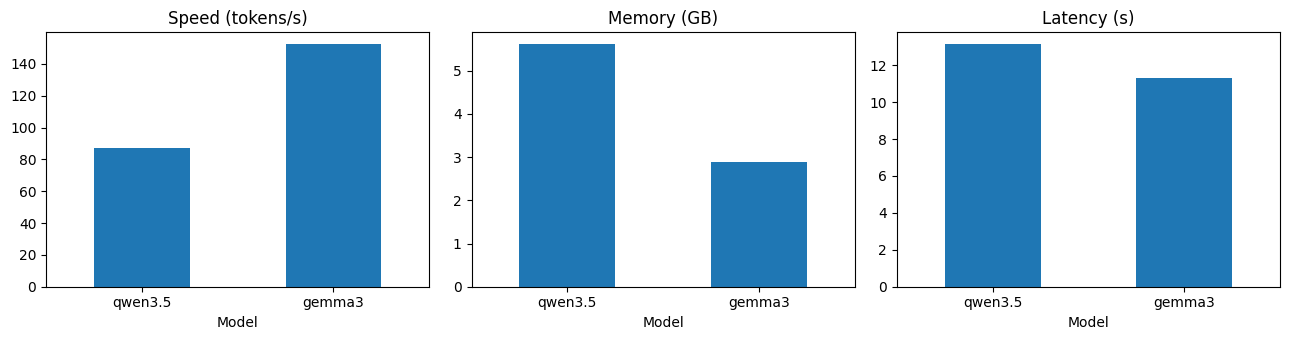

In [91]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

>On my laptop, which has an NVIDIA RTX 5080 Laptop with 16 GB of VRAM gemma3 produced 152 tokens per second compared to 87 for qwen3.5, which's 1.7 times faster. Gemma3 also used 2.88 GB of VRAM while qwen3.5 used 5.61 GB, roughly half as much. Both models loaded in 3 to 4 seconds and ran entirely on the GPU. Qwen3.5, the model with 9.0 billion parameters and Q4_K_M quantization performed better in Part 6 so the extra memory does provide some quality but not a huge difference on these tasks. The trade‑off is simple: a larger model usually delivers quality but requires more memory has higher latency and needs better hardware. A smaller model runs faster. Fits on weaker machines but may be less accurate or less detailed. Choosing a model should rely on measurements on the target machine just as I did here and on the task. If I need interactive answers or have a laptop, with limited VRAM I would pick gemma3. If I face reasoning or need a code review I would pick qwen3.5 because my 16 GB GPU can accommodate it.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [92]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [93]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [94]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [97]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Overwriting LocalAI_Lab/source/templates/index.html


In [98]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Overwriting LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [101]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward, with the goal of learning a policy that maximizes cumulative reward. Common algorithms include Q-learning and policy gradients.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 36.16s · 6.8 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn a mapping from inputs to outputs (such as classification or regression). Additionally, machine learning includes unsupervised learning, which works with unlabelled data to discover structure like clusters.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 11.58s · 6.7 tok/s

Q: 

In [102]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

>Local AI means running and loading an AI model on a computer or private server.rather than using the online services that provide AI services via the cloud infrastructure. All the prompts, documents, and answers are stored locally, and it operates even without being connected to the Internet. In this experiment, Ollama used qwen3.5 locally on my personal GPU, and it worked fine without Wi-Fi.

**Q2.** Difference between a Cloud LLM and a Local LLM?

>Cloud LLMs are hosted by a service provider and accessed via the internet via their API. They require no hardware from my side and can be very large and powerful, but the data goes out of system, they depend to the availability of the service provider, they may also require subscription or payement for each request. On the other hand, a local LLM is installed on my own device and it offer better control over my data and can work offline. but it is limited by the hardware(RAM, GPU).

**Q3.** What role does Ollama play?

>Ollama is a tools that enables me to download, deploy, and run large language models locally. It manages the whole process of loading the model, memory management, and inference.
Moreover, Ollama offers a REST API which facilitates communication between my Python application and the locally running model. During my test, Ollama deployed Qwen 3.5 and Gemma 3 on my GPU, while my Python application communicated with the Ollama server.

**Q4.** What is model quantization?

>Model quantization is the method of lowering the precision with which the weights of the model are represented. For instance, instead of using 16-bit or 32-bit floats to store the model's weights, it is possible to employ low-precision formats such as 4-bit.
The process decreases the amount of memory the model uses and allows running larger models on constrained hardware. Nevertheless, model quantization may decrease the performance or accuracy of the model.
based on this experience  we demonstrated that Qwen 3.5 used Q4_K_M quantization and was able to run on my GPU.

**Q5.** Why does model size affect memory consumption?

>The model size influences the amount of memory used because each parameter of the model needs memory storage for holding it.
The bigger the model is, the more memory will be required by the model to load it and execute the inference process. Memory usage depends on the weight precision, context length, and memory required for the computations.
As an illustration, Qwen 3.5 needed about 5.61 GB of VRAM, whereas Gemma 3 required about 2.88 GB in my testing. Thus, the model size increased memory usage on the GPU by nearly two times.

**Q6.** Why can a smaller model sometimes be preferable?

>The use of the small model is beneficial because it will use less memory, provide faster responses in many cases, and will be able to work even on lower machines.
Such a model will be convenient when fast responses are needed or when several users need to work with the model at once.
Although bigger models might produce higher quality of work, the small model will be sufficient for simple tasks like summarization or classification of a document.
Consequently, the decision regarding the model depends on the specific case.

**Q7.** Advantages of local inference?

>Local inference has a number of benefits:
    . Privacy: Confidential information can be stored locally on my computer.
    . Access offline: The model can function offline once it has been downloaded.
    . Control: I have the ability to select the model and set its parameters.
    . Cost: There is no cost per request using my own hardware.
    . Availability: The program doesn’t rely on an external cloud provider.
    . Customization: Local models can be incorporated into private documents and applications.
In our experiment, I managed to run Qwen 3.5 locally and communicate with it via Python without using any cloud API.

**Q8.** Disadvantages of local inference?

>Disadvantages of local inference include:
    . Hardware restrictions: The size of the model depends on the amount of RAM and VRAM available.
    . Speed: Local models may perform slower than cloud-based models that operate on high-performance servers.
    . Model quality: The smaller local models may give less accurate or detailed answers.
    . Setup process: Downloading and setting up models requires certain technical skills.
    . Maintenance: I am in charge of managing the models and the local application.
    . Power consumption: Running models locally takes energy and may produce heat.
Moreover, local inference does not necessarily ensure the privacy and security of data. The application and server should be properly set up too.

**Q9.** Explain the architecture of your Python application.

>The structure of my application follows client-server architecture. Here the user interfaces via a web interface that was built using Flask, and the Python application accesses Ollama using its REST API.
Main Components:
    - Browser: Interfaces with the user where he enters his questions.
    - Flask Application: Takes the questions entered by the user and handles the application logic.
    - Conversation history: Keeps track of previous messages to provide context to the conversations.
    - Document retriever: Performs the search of relevant information among the local documents.
    - Ollama Server: Gets the request and runs the chosen local LLM.
    - Local LLM: Gets the prompt and context and generates the answer.
    - Display response time: Displays the answer to the browser along with the response time.
>Main architecture:
    Browser → Flask/Python → Conversation History + Document Retriever → Ollama → Local LLM → Answer → Browser.
The application also supports JSON response to the selected questions.

**Q10.** Explain the role of the REST API.

>REST API facilitates communication between multiple apps through HTTP requests.
In our case, the Python app makes an HTTP POST request to the Ollama server located at http://localhost:11434/api/chat or http://localhost:11434/api/generate.
Information like the name of the model, prompt or messages, and generation settings is included in this request.
The server processes this request using the local model and provides a JSON response with the answer and additional metadata.
Using the REST API makes it possible to use the local LLM in the Python application without implementing its inference algorithm directly.

**Q11.** What is RAG?

>Retrieval Augmented Generation (RAG) refers to a method combining information retrieval and text generation.
The application doesn’t solely depend on the information contained in the parameters of the model but, rather, first finds relevant information in external documents. That information is then presented to the LLM as context in order to come up with an answer.
In our experiment, the application searches the local documents, finds the necessary information, and sends it to Ollama along with the question.

**Q12.** Difference between an LLM and a multimodal LLM?

>A classic large language model LLM only works with text, it takes text as input and Gives text as output. A multimodal model is different. It can take various type as input such as images. Then it connects the images to the text prompt. To do this it has a part called a vision encoder. This encoder turns the image into a set of numbers or embeddings. These embeddings can then be used by the language model. The language model combines these embeddings with the words, from the prompt. This way the model understands both the text and the image together.

**Q13.** Compare two local models experimentally.

>In our experiment, we tested Qwen 3.5 and Gemma 3 using the same prompt about programming in Python. Both models managed to generate a function that could be used to check if a number is a prime.
It appeared that both models generated a correct implementation, but there were some differences in terms of response time, generation speed, memory usage, and coding style.
| Criterion | Qwen 3.5 | Gemma 3 |
|---|------|--------|
|Model parameters |9.0B | Smaller model|
| Disk size | 6.6 GB| 3.4 GB |
|VRAM consumption| 5.61 GB| 2.88 GB|
|Response time| 16.3 s| 20.2 s |
| Generation speed| 85.1 tokens/s| 147.0 tokens/s |
| Generated tokens| 703| 904|
| Code correctness| Correct on tested inputs| Correct for n ≥ 2 |
| GPU execution| 100% GPU| 100% GPU|

>The measurements were taken on my NVIDIA RTX 5080 Laptop GPU.
Gemma 3 was superior regarding generating tokens, taking approximately 147 tokens per second, while Qwen 3.5 took 85.1 tokens per second.
Nevertheless, Qwen 3.5 had a shorter response time since it generated less tokens. Code qualitywise, Qwen 3.5 had an algorithm that optimized checking divisors in the form of 6k ± 1. Gemma 3 was implementing a trial division algorithm. Both codes were correct for valid input numbers in the measured range. Almost twice the amount of VRAM was consumed by Qwen 3.5 than by Gemma 3. Consequently, Qwen 3.5 offered a better solution in terms of optimization but needed more memory.
The example demonstrates that the biggest model is not always the most optimal solution for any task.


**Q14.** Which model would you deploy on a computer with limited RAM? Explain.
>I prefer to use Gemma 3 with limited memory available on the computer or GPU memory available. The amount of required VRAM was about 2.88 GB for Gemma 3 in my experiments while Qwen 3.5 needed 5.61 GB of VRAM. In addition, Gemma 3 worked faster in terms of generation with 147 tokens/second rate.
While Qwen 3.5 had generated more optimized code in my programming test, Gemma 3 was also able to generate valid codes with valid inputs.
Thus, it can be stated that Gemma 3 is a preferable option for a computer with limited memory resources taking into consideration the generation speed and amount of used VRAM. Nevertheless, this choice depends on specific tasks.

**Q15.** What security risks exist when exposing a local LLM server to a network?

>Connecting the local LLM server to the network creates several potential security threats.
Firstly, Ollama doesn't offer authentication capabilities by default. When the server is connected with the command OLLAMA_HOST=0.0.0.0, other devices on the network can access it. Unauthorized individuals can send requests to the server, use GPU power, or disrupt the application.
Secondly, the server will reveal sensitive information if the application processes private documents or a conversation history. The attacker can get the information with unauthorized requests.
The third threat is the possibility of prompt injection through the documents. The malicious document might include instructions that would cause the model to ignore the initial instructions or reveal sensitive information.

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [2]:
import os
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
